# moonshot_compounding — Mutual-Information Screen (driver)

**What this notebook does.** Runs a point-in-time cross-sectional
mutual-information screen over the frozen feature panel: for each
(feature, forward-horizon) it reports `MI_excess = raw_MI − within-date-shuffle
null`, per date, with a bootstrap CI over dates. Plus a feature×feature
redundancy matrix.

**Run order (top to bottom):**
1. Cell A — mount + preflight (fails loudly on a stale mount)
2. Cell B — put `mi_screen.py` + `synthetic_selftest.py` on the path
3. Cell C — **self-test guard** (refuses to proceed to real data if it fails)
4. Cell D — load the real panel + Amihud (schema-checked)
5. Cell E — run the screen (training only, hold-out guarded)
6. Cell F — redundancy matrix
7. Cell G — save artifacts + plots under `hypotheses/mi_screen/run_<date>/`

**Discipline baked in:** training window 2010–2021 only; any forward window
crossing 2021-12-31 is dropped (hold-out untouched); `flag == 1` explicit;
Amihud lagged M−1 and edge months dropped; missing obs dropped never zeroed;
files dated, never overwritten.

**This is a characterization run, not a strategy-selection run.** The output is
a flat landscape. It is deliberately NOT ranked into a 'winner' — choosing a
feature/horizon off this map is what starts the multiple-testing clock (DSR).


## Cell A — mount + preflight

In [9]:

from pathlib import Path
import pandas as pd, numpy as np, datetime as dt

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("mount note:", e)

BASE = Path("/content/drive/MyDrive/moonshot_compounding")
assert BASE.exists(), f"BASE not found: {BASE} — wrong path or unmounted."

# Stale-mount detector (fact #23): the tree can sync while contents don't.
n_parquet = len(list((BASE/"features").glob("*.parquet")))
print("features/*.parquet visible:", n_parquet)
assert n_parquet >= 2, ("Fewer parquet files than expected — likely a STALE MOUNT. "
    "Fix: Runtime > Disconnect and delete runtime, then remount. NOT lost data.")

TODAY = dt.date.today().isoformat()
RUN_DIR = BASE / "hypotheses" / "mi_screen" / f"run_{TODAY}"
print("run dir will be:", RUN_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
features/*.parquet visible: 20
run dir will be: /content/drive/MyDrive/moonshot_compounding/hypotheses/mi_screen/run_2026-08-10


## Cell B — load the screen module

Upload `mi_screen.py` and `synthetic_selftest.py` to the Colab session (or keep
them in Drive and point `MODULE_DIR` at them). This cell puts them on `sys.path`
and imports.

In [10]:

import sys
# Option 1: files uploaded to the Colab working dir (default).
MODULE_DIR = Path(".")
# Option 2: if you keep them in Drive, uncomment and set:
# MODULE_DIR = BASE / "code" / "mi_screen"

sys.path.insert(0, str(MODULE_DIR.resolve()))
for f in ["mi_screen.py", "synthetic_selftest.py"]:
    assert (MODULE_DIR/f).exists(), f"{f} not found in {MODULE_DIR.resolve()} — upload it."

import importlib, mi_screen as M, synthetic_selftest as S
importlib.reload(M); importlib.reload(S)

# Run settings (industry-standard choice: 15 shuffles for a clean null floor).
M.N_SHUFFLE = 15
M.N_BOOT = 500
print("mi_screen loaded. N_SHUFFLE =", M.N_SHUFFLE, "| N_BOOT =", M.N_BOOT)
print("TRAIN_END (hold-out wall):", M.TRAIN_END.date())


mi_screen loaded. N_SHUFFLE = 15 | N_BOOT = 500
TRAIN_END (hold-out wall): 2021-12-31


## Cell C — SELF-TEST GUARD (must pass before real data)

This runs the synthetic self-test: a planted signal must be detected, a noise
feature must read null, and the leakage / PIT-universe / hold-out / warm-up
guards must all pass. **If this cell raises, do not proceed** — the machinery is
not trustworthy on real data.

In [11]:

print("Running synthetic self-test (planted-signal + null + leakage guards)...")
S.main()   # raises AssertionError on any failure
print("\n>>> SELF-TEST GUARD PASSED — safe to run on real data.")


Running synthetic self-test (planted-signal + null + leakage guards)...
SYNTHETIC SELF-TEST
panel: 3654 dates x 120 tickers

[warm-up] first momentum signal at 2008-12-18 (needs >= 2008-12-18): OK
[universe] T000 excluded 2015-04-30 (flagged out): OK; included 2016-04-29: OK
[leakage] feature latest=2016-04-29 <= t=2016-04-29 and fwd future leg=2016-05-30 > t: OK
[hold-out] late-2021 rebalance 2021-12-31 @1y dropped: OK
[nan-roll] median stk/date  strict=0  fixed=83 (strict collapses, fixed survives)

[screen] running MI-excess on planted vs noise @ 1m horizon ...
        planted_feat |  1m: MI_excess=+0.1348 CI[+0.1233,+0.1456] * (n_dates=138, ~120 stk/date)
          noise_feat |  1m: MI_excess=+0.0041 CI[-0.0022,+0.0107]   (n_dates=138, ~120 stk/date)
       momentum_12_1 |  1m: MI_excess=+0.0046 CI[-0.0008,+0.0108]   (n_dates=138, ~120 stk/date)

--- ground-truth assertions ---
planted MI_excess=+0.1348 CI[+0.1233,+0.1456] sig=True
noise   MI_excess=+0.0041 CI[-0.0022,+0.0107] sig=

## Cell D — load the real panel + Amihud (schema-checked)

Newest-wins resolver (your convention). `build_panel` asserts the schema and
normalizes the `Date` unit (fact #27); it fails loudly on any drift.

In [12]:

def newest(folder, stem):
    fs = sorted((BASE/folder).glob(f"{stem}_*.parquet"))
    assert fs, f"no {stem}_*.parquet in {folder}"
    return fs[-1]

dp_path = newest("features", "feature_panel_with_pit_v2")
am_path = newest("features", "amihud_monthly_v2")
print("daily :", dp_path.name)
print("amihud:", am_path.name)

daily = pd.read_parquet(dp_path)
amihud = pd.read_parquet(am_path)

panel = M.build_panel(daily, amihud)
print("panel:", len(panel.dates), "dates x", len(panel.tickers), "tickers")
print("date range:", panel.dates.min().date(), "->", panel.dates.max().date())

# Coverage sanity: flag distribution and Amihud edge-month drop count.
_ = M.feat_amihud_lagged(panel)   # triggers the edge-month drop counter
print("amihud edge-months dropped:", getattr(M.feat_amihud_lagged, "_dropped_edge", "n/a"))

# Assert none of our TRAIN rebalances land on a vendor_failure date (fact #24/#25).
reb = M.month_end_rebalance_dates(panel)   # already restricted to <= TRAIN_END
vf = [t for t in reb if panel.date_status.get(t, "ok") == "vendor_failure"]
print(f"train rebalance dates: {len(reb)} | on vendor_failure: {len(vf)}")
assert len(vf) == 0, f"rebalance dates on vendor_failure: {vf} — investigate before trusting."
print("first/last train rebalance:", reb.min().date(), reb.max().date())


daily : feature_panel_with_pit_v2_2026-07-24.parquet
amihud: amihud_monthly_v2_2026-07-24.parquet
panel: 4237 dates x 1069 tickers
date range: 2010-01-04 -> 2026-07-10
amihud edge-months dropped: 2138
train rebalance dates: 144 | on vendor_failure: 0
first/last train rebalance: 2010-01-29 2021-12-31


## Cell E — run the screen (6 features × 5 horizons × 3 lookbacks)

Training only; hold-out guarded per horizon. Prints the flat landscape with a
`*` on any cell whose bootstrap CI excludes zero. Expect ~30–60 min at
N_SHUFFLE=15 on the full universe.

In [13]:

import time
t0 = time.time()
results = M.run_screen(panel, verbose=True)
print(f"\nscreen done in {(time.time()-t0)/60:.1f} min")


       momentum_12_1 |  1w: MI_excess=+0.0264 CI[+0.0201,+0.0338] * (n_dates=110, ~481 stk/date)
       momentum_12_1 |  1m: MI_excess=+0.0316 CI[+0.0242,+0.0390] * (n_dates=108, ~464 stk/date)
       momentum_12_1 |  3m: MI_excess=+0.0409 CI[+0.0322,+0.0488] * (n_dates=104, ~468 stk/date)
       momentum_12_1 |  6m: MI_excess=+0.0337 CI[+0.0268,+0.0407] * (n_dates=104, ~483 stk/date)
       momentum_12_1 |  1y: MI_excess=+0.0337 CI[+0.0266,+0.0406] * (n_dates=97, ~480 stk/date)
         reversal_1m |  1w: MI_excess=+0.0187 CI[+0.0120,+0.0239] * (n_dates=121, ~486 stk/date)
         reversal_1m |  1m: MI_excess=+0.0224 CI[+0.0172,+0.0272] * (n_dates=119, ~473 stk/date)
         reversal_1m |  3m: MI_excess=+0.0152 CI[+0.0114,+0.0195] * (n_dates=114, ~477 stk/date)
         reversal_1m |  6m: MI_excess=+0.0118 CI[+0.0069,+0.0168] * (n_dates=115, ~486 stk/date)
         reversal_1m |  1y: MI_excess=+0.0203 CI[+0.0153,+0.0261] * (n_dates=105, ~487 stk/date)
             rvol_60 |  1w: MI_

## Cell F — feature × feature redundancy matrix

In [14]:

red = M.feature_redundancy_matrix(panel)
print("MI_excess between features (higher = more redundant):")
print(red.round(4).to_string())


/content/mi_screen.py:593: UserWarning: [redundancy] log_turnover_21<->amihud_illiq MI_excess=1.2746 exceeds ceiling 0.3; 0.0% of dates have |rank-corr|>0.999 (degenerate cross-section). Reporting as NaN + flagging.
  warnings.warn(


MI_excess between features (higher = more redundant):
                   momentum_12_1  reversal_1m  rvol_60  log_turnover_21  overnight_tilt_21  amihud_illiq
momentum_12_1                NaN       0.0360   0.1103           0.0232             0.0232        0.0308
reversal_1m               0.0360          NaN   0.0899           0.0159             0.0252        0.0111
rvol_60                   0.1103       0.0899      NaN           0.0124             0.0369        0.0234
log_turnover_21           0.0232       0.0159   0.0124              NaN             0.0498           NaN
overnight_tilt_21         0.0232       0.0252   0.0369           0.0498                NaN        0.0652
amihud_illiq              0.0308       0.0111   0.0234              NaN             0.0652           NaN


## Cell G — save artifacts + plots (dated, never overwritten)

Writes to `hypotheses/mi_screen/run_<date>/`:
- `mi_landscape_<date>.csv` — every (feature,horizon) cell, flat
- `mi_lookback_<date>.csv` — the stationarity probe (per-lookback means)
- `feature_redundancy_<date>.csv` — the redundancy matrix
- `mi_results_<date>.json` — full nested results (machine artifact)
- `mi_heatmap_excess_<date>.png` — MI_excess heatmap (feature × horizon)
- `mi_heatmap_sig_<date>.png` — significance mask heatmap


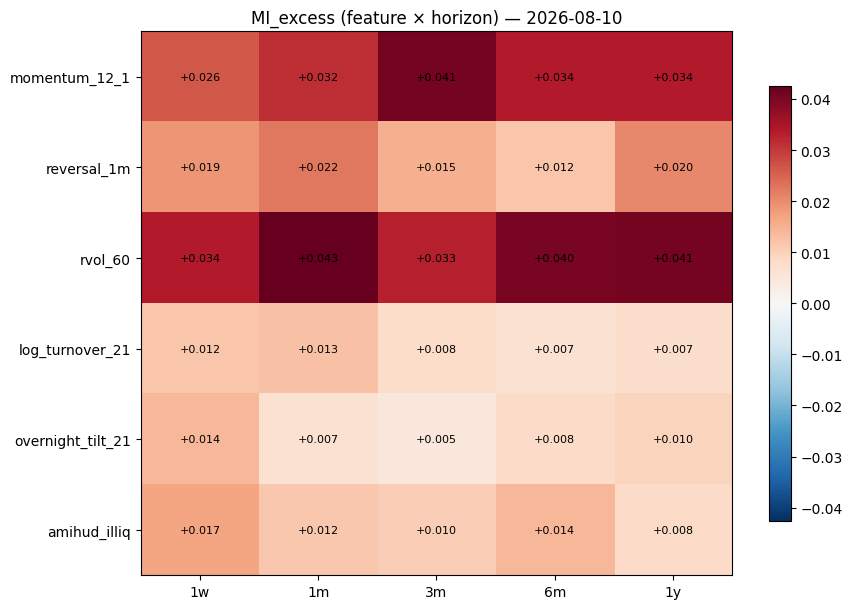

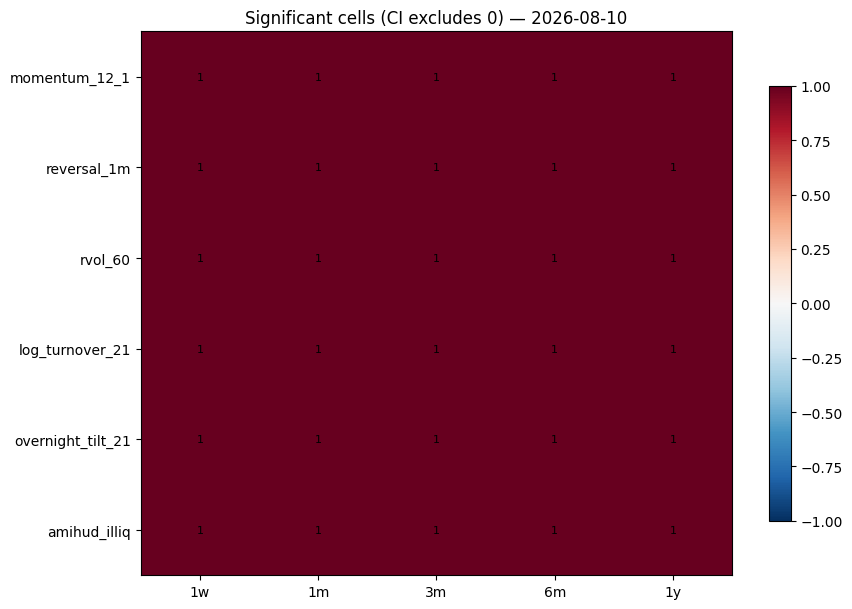

saved to: /content/drive/MyDrive/moonshot_compounding/hypotheses/mi_screen/run_2026-08-10
   feature_redundancy_2026-08-10.csv
   mi_heatmap_excess_2026-08-10.png
   mi_heatmap_sig_2026-08-10.png
   mi_landscape_2026-08-10.csv
   mi_lookback_2026-08-10.csv
   mi_results_2026-08-10.json


In [15]:

import json, matplotlib.pyplot as plt

RUN_DIR.mkdir(parents=True, exist_ok=True)

# Refuse same-day overwrite (project rule): if the landscape file exists, stop.
land_path = RUN_DIR / f"mi_landscape_{TODAY}.csv"
assert not land_path.exists(), f"{land_path} exists — refusing same-day overwrite. Delete to rebuild."

# Flatten landscape.
feat_order = list(M.FEATURES.keys())
hz_order = list(M.HORIZONS.keys())
land_rows, lb_rows = [], []
for f in feat_order:
    for h in hz_order:
        c = results.get(f, {}).get(h, {})
        if "mi_excess" not in c:
            land_rows.append(dict(feature=f, horizon=h, note=c.get("note", "missing")))
            continue
        land_rows.append(dict(feature=f, horizon=h,
            mi_excess=c["mi_excess"], ci_low=c["ci_low"], ci_high=c["ci_high"],
            sig=c["sig"], n_dates=c["n_dates"], n_dropped=c.get("n_dropped"),
            mean_stocks_per_date=c["mean_stocks_per_date"]))
        for L, v in c.get("lookback", {}).items():
            lb_rows.append(dict(feature=f, horizon=h, lookback=L,
                mean=v["mean"], min=v["min"], max=v["max"], n_windows=v["n_windows"]))

land = pd.DataFrame(land_rows)
lb = pd.DataFrame(lb_rows)
land.to_csv(land_path, index=False)
lb.to_csv(RUN_DIR / f"mi_lookback_{TODAY}.csv", index=False)
red.to_csv(RUN_DIR / f"feature_redundancy_{TODAY}.csv")
with open(RUN_DIR / f"mi_results_{TODAY}.json", "w") as fh:
    json.dump(results, fh, default=str, indent=2)

# Heatmaps.
def heat(mat, title, fname, fmt="{:+.3f}"):
    fig, ax = plt.subplots(figsize=(1.4*len(hz_order)+2, 0.7*len(feat_order)+2))
    im = ax.imshow(mat, aspect="auto", cmap="RdBu_r",
                   vmin=-np.nanmax(np.abs(mat)), vmax=np.nanmax(np.abs(mat)))
    ax.set_xticks(range(len(hz_order))); ax.set_xticklabels(hz_order)
    ax.set_yticks(range(len(feat_order))); ax.set_yticklabels(feat_order)
    for i in range(len(feat_order)):
        for j in range(len(hz_order)):
            v = mat[i, j]
            if not np.isnan(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8)
    ax.set_title(title); fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout(); fig.savefig(RUN_DIR / fname, dpi=130); plt.show()

excess_mat = np.full((len(feat_order), len(hz_order)), np.nan)
sig_mat = np.zeros((len(feat_order), len(hz_order)))
for i, f in enumerate(feat_order):
    for j, h in enumerate(hz_order):
        c = results.get(f, {}).get(h, {})
        if "mi_excess" in c:
            excess_mat[i, j] = c["mi_excess"]
            sig_mat[i, j] = 1.0 if c["sig"] else 0.0

heat(excess_mat, f"MI_excess (feature × horizon) — {TODAY}",
     f"mi_heatmap_excess_{TODAY}.png")
heat(sig_mat, f"Significant cells (CI excludes 0) — {TODAY}",
     f"mi_heatmap_sig_{TODAY}.png", fmt="{:.0f}")

print("saved to:", RUN_DIR)
for p in sorted(RUN_DIR.glob(f"*{TODAY}*")):
    print("  ", p.name)


In [16]:
# Why do turnover_21 / overnight_21 lose half the rebalance dates?
import numpy as np, pandas as pd
reb = M.month_end_rebalance_dates(panel)

def coverage(feat_wide, name):
    per_date = []
    for t in reb:
        row = feat_wide.loc[t]
        elig = (panel.flag.loc[t] == 1) & row.notna()
        per_date.append(int(elig.sum()))
    per_date = np.array(per_date)
    n_ok = int((per_date >= M.MIN_STOCKS_PER_DATE).sum())
    print(f"{name:>18}: dates>=30stk = {n_ok:3d}/{len(reb)}  "
          f"median stk/date = {np.median(per_date):.0f}  "
          f"min = {per_date.min()}")

coverage(M.feat_momentum_12_1(panel), "momentum_12_1")
coverage(M.feat_reversal_1m(panel),   "reversal_1m")
coverage(M.feat_rvol60(panel),        "rvol_60")
coverage(M.feat_log_turnover_21(panel),   "log_turnover_21")
coverage(M.feat_overnight_tilt_21(panel), "overnight_tilt_21")

# Direct: how often is the UNDERLYING NaN on rebalance rows?
for nm, fr in [("turnover", panel.turnover), ("overnight_return", panel.overnight_ret),
               ("daily_return", panel.daily_ret), ("Close", panel.close)]:
    nan_frac = np.mean([fr.loc[t].isna().mean() for t in reb])
    print(f"{nm:>16}: mean NaN-fraction on rebalance rows = {nan_frac:.3f}")

     momentum_12_1: dates>=30stk = 115/144  median stk/date = 492  min = 0
       reversal_1m: dates>=30stk = 126/144  median stk/date = 496  min = 0
           rvol_60: dates>=30stk = 134/144  median stk/date = 488  min = 0
   log_turnover_21: dates>=30stk = 134/144  median stk/date = 497  min = 0
 overnight_tilt_21: dates>=30stk = 134/144  median stk/date = 497  min = 0
        turnover: mean NaN-fraction on rebalance rows = 0.312
overnight_return: mean NaN-fraction on rebalance rows = 0.313
    daily_return: mean NaN-fraction on rebalance rows = 0.313
           Close: mean NaN-fraction on rebalance rows = 0.312


In [17]:
# Diagnose the turnover<->amihud redundancy inflation on the REAL panel.
import numpy as np, pandas as pd
fa = M.feat_log_turnover_21(panel)
fb = M.feat_amihud_lagged(panel)
reb = M.month_end_rebalance_dates(panel)
rng2 = np.random.default_rng(0)
rec = []
for t in reb:
    elig = (panel.flag.loc[t] == 1) & fa.loc[t].notna() & fb.loc[t].notna()
    n = int(elig.sum())
    if n < M.MIN_STOCKS_PER_DATE:
        continue
    fr = M._rank01(fa.loc[t][elig].to_numpy(float))
    yr = M._rank01(fb.loc[t][elig].to_numpy(float))
    mi = M._ksg_mi(fr, yr, rng2)
    amv = fb.loc[t][elig]
    rec.append((t.date(), n, round(mi,4), amv.nunique(), round(1-amv.nunique()/n,3)))
r = pd.DataFrame(rec, columns=['date','n','ksg_mi','amihud_unique','amihud_tie_frac'])
print(r['ksg_mi'].describe().round(4).to_string())
print("\ndates with MI > 0.3:")
print(r[r.ksg_mi > 0.3].to_string(index=False))
print("\ncorrelation of ksg_mi with amihud_tie_frac:",
      round(r['ksg_mi'].corr(r['amihud_tie_frac']), 3))

count    134.0000
mean       1.2868
std        0.1292
min        0.9743
25%        1.2029
50%        1.2993
75%        1.3787
max        1.5426

dates with MI > 0.3:
      date   n  ksg_mi  amihud_unique  amihud_tie_frac
2010-06-30 499  1.3273            499              0.0
2010-07-30 498  1.3001            498              0.0
2010-08-31 498  1.1123            498              0.0
2010-09-30 498  1.2721            498              0.0
2010-10-29 498  1.1372            498              0.0
2010-11-30 497  1.3786            497              0.0
2010-12-31 498  1.3601            498              0.0
2011-01-31 497  1.5426            497              0.0
2011-02-28 497  1.4550            497              0.0
2011-03-31 495  1.4311            495              0.0
2011-04-29 497  1.2770            497              0.0
2011-05-31 496  1.4876            496              0.0
2011-06-30 496  1.4047            496              0.0
2011-07-29 496  1.4200            496              0.0
2011-09-3

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


---
**After this runs:** paste me the `mi_landscape` table (or the printed screen
output) and I'll write the log entry with the numbers filled in. I'll present
the flat landscape without ranking a winner — per the DSR reasoning, eyeballing
a winner off this map is what starts the multiple-testing clock.
